# SMS Spam Detection

This notebook classifies SMS messages as ham or spam.

## 1. Dataset Loading and Validation

Load the UCI dataset and check its size, labels, missing values, and duplicates.

In [1]:
import os
import csv
import urllib.request
import zipfile
import pandas as pd

pd.set_option("display.max_colwidth", 120)

data_path = "data/SMSSpamCollection"

if os.path.exists(data_path):
    print("Using the dataset already available in the project.")
elif os.path.exists("../data/SMSSpamCollection"):
    data_path = "../data/SMSSpamCollection"
    print("Using the dataset already available in the project.")
else:
    os.makedirs("data", exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    zip_path = "data/sms.zip"
    urllib.request.urlretrieve(url, zip_path)
    zip_file = zipfile.ZipFile(zip_path, "r")
    zip_file.extractall("data")
    zip_file.close()
    os.remove(zip_path)
    print("Dataset downloaded from UCI.")

data_path

Dataset downloaded from UCI.


'data/SMSSpamCollection'

In [2]:
df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

Rows: 5,574
Columns: 2


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [3]:
print("Missing labels:", df["label"].isnull().sum())
print("Missing messages:", df["message"].isnull().sum())
print("Empty messages:", (df["message"].str.strip() == "").sum())
print("Duplicate rows:", df.duplicated().sum())
print("Labels:", df["label"].unique())

Missing labels: 0
Missing messages: 0
Empty messages: 0
Duplicate rows: 403
Labels: <StringArray>
['ham', 'spam']
Length: 2, dtype: str


In [4]:
class_counts = df["label"].value_counts().rename("count").to_frame()
class_counts["percentage"] = (class_counts["count"] / len(df) * 100).round(2)
class_counts

,count,percentage
label,,
ham,4827,86.6
spam,747,13.4


### Initial observations

The dataset has more ham than spam messages. Later evaluation will therefore include precision, recall, and F1-score.

## 2. Simple Data Exploration

Compare class counts and message lengths.

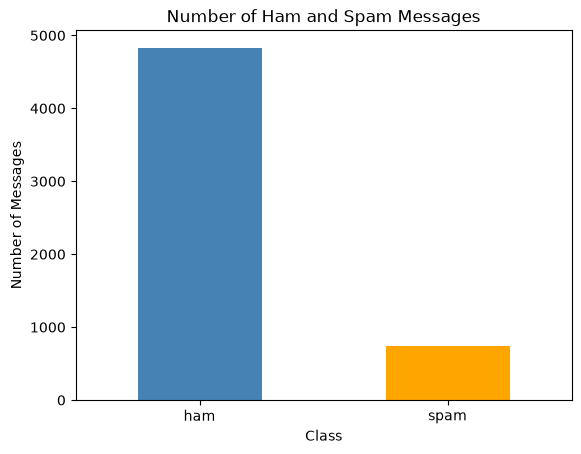

In [5]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar", color=["steelblue", "orange"])
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [6]:
df["message_length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

length_summary = df.groupby("label")[["message_length", "word_count"]].mean().round(2)
length_summary

,message_length,word_count
label,,
ham,71.47,14.30
spam,138.68,23.91


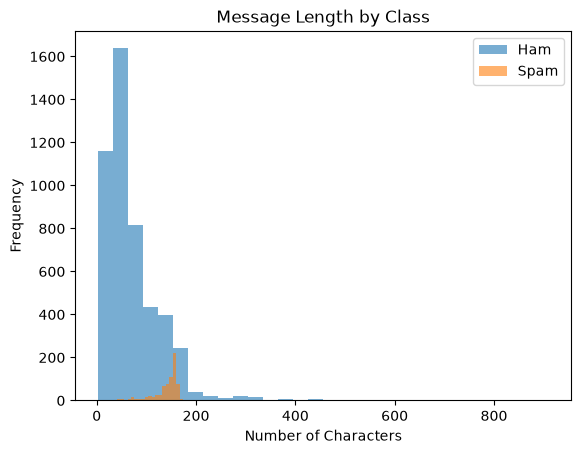

In [7]:
df[df["label"] == "ham"]["message_length"].plot(kind="hist", bins=30, alpha=0.6, label="Ham")
df[df["label"] == "spam"]["message_length"].plot(kind="hist", bins=30, alpha=0.6, label="Spam")
plt.title("Message Length by Class")
plt.xlabel("Number of Characters")
plt.legend()
plt.show()

### Short observations

- Most messages are ham (86.6%).
- Spam messages are longer on average: 138.68 characters versus 71.47 for ham.

## 3. Text Preprocessing

Clean the messages for TF-IDF and the classical classification models.

In [8]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " url " , text)
    text = re.sub(r"\d+", " number " , text)
    text = re.sub(r"[^a-z\s]", " " , text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [stemmer.stem(word) for word in words]
    return " ".join(words)

df["clean_message"] = df["message"].apply(preprocess_text)
df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entri number wkli comp win fa cup final tkt number st may number text fa number receiv entri question std txt r...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives around here though",nah think goe usf live around though


In [9]:
examples = df.groupby("label").head(2)
examples[["label", "message", "clean_message"]]

,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entri number wkli comp win fa cup final tkt number st may number text fa number receiv entri question std txt r...
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,freemsg hey darl number week word back like fun still tb ok xxx std chg send number number rcv


### Why these steps?

- Lowercase makes words such as `FREE` and `free` the same.
- URLs and numbers are replaced because they are common in spam.
- Punctuation and common stopwords are removed to reduce noise.
- Stemming groups related word forms.
- The original message is kept for the BERT model later.